# Logistic Regression on a Synthetic 1-Feature Dataset

In [8]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import numpy as np

## Exploring the Synthetic 1-Feature Classification Dataset

For this experiment, we use a **synthetic 1D dataset** generated with `make_classification` from `scikit-learn`.
This dataset is designed to be **linearly separable** along a single feature, making it ideal to visualize the **sigmoid curve** of Logistic Regression.

### Dataset Structure

* **Features (`X`)**: One numerical attribute per sample (denoted as `x`)

  * Determines the position of each data point along a 1D axis.

* **Target (`y`)**: Binary class labels (0 or 1)

  * `0` → belongs to the negative class
  * `1` → belongs to the positive class

* **Dataset size**: Typically **100–150 samples**, which keeps the visualization clear and interpretable.

* **Separation**: Controlled by the `class_sep` parameter in `make_classification`, ensuring that the two classes are **well separated** along the feature axis.

### Why a Synthetic 1D Dataset?

* It allows **full control** over the data distribution.
* The 1D feature setup makes it easy to **plot the logistic sigmoid curve** and visually inspect the decision boundary at probability 0.5.
* Ideal for **teaching and demonstration purposes**, since real-world datasets often have multiple dimensions and complex relationships that are hard to visualize.

In [9]:
# Generate a linearly separable 1D dataset
X, y = make_classification(
    n_samples=150,
    n_features=1,      # 1 feature for visualization
    n_informative=1,
    n_redundant=0,
    n_clusters_per_class=1,
    flip_y=0,
    class_sep=2,
    random_state=0
)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

# Inspect
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nFirst 10 samples:\n", X[:10])
print("Corresponding labels:\n", y[:10])

Shape of X: (150, 1)
Shape of y: (150,)

First 10 samples:
 [[ 1.43489512]
 [-1.67941155]
 [-1.53420685]
 [-1.86648122]
 [-2.26882707]
 [-1.48965802]
 [-2.61426965]
 [ 2.80524246]
 [-2.25769736]
 [ 0.83049416]]
Corresponding labels:
 [1 0 0 0 0 0 0 1 0 1]


In [13]:
# Train Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred_prob = model.predict_proba(X_test)[:, 1]  # Probability for class 1
y_pred_class = model.predict(X_test)

In [16]:
# Test Accuracy
accuracy = np.mean(y_pred_class == y_test)
print(f"Accuracy of Logistic Regression: {accuracy:.2f}")

Accuracy of Logistic Regression: 1.00


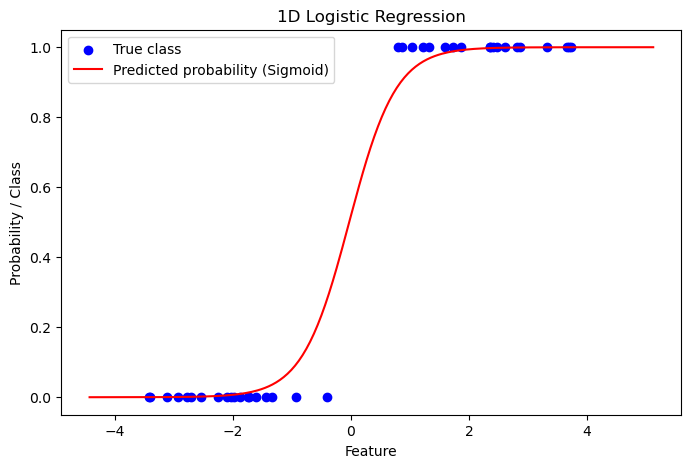

In [19]:
# Plot probabilities (S-curve) and actual points
X_plot = np.linspace(X.min() - 1, X.max() + 1, 300).reshape(-1, 1)
y_plot_prob = model.predict_proba(X_plot)[:, 1]

plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, color='blue', label='True class')
plt.plot(X_plot, y_plot_prob, color='red', label='Predicted probability (Sigmoid)')
plt.xlabel('Feature')
plt.ylabel('Probability / Class')
plt.title('1D Logistic Regression')
plt.legend()
plt.savefig("logistic_regression_1d.png", dpi=300, bbox_inches='tight')
plt.show()

For this 1D synthetic dataset, Logistic Regression clearly separates the two classes using a **sigmoid curve**, mapping the feature values to probabilities. The predicted probabilities closely follow the true class labels, illustrating how the model smoothly transitions between the negative and positive class.